# **Pie Chart 기본기 익히기**

matplotlib의 파이 그래프를 학습하기 위한 실습입니다.

## **한글 폰트 설치**

In [1]:
# !pip install -q koreanize-matplotlib
# import koreanize_matplotlib
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# plt.rcParams['axes.unicode_minus'] = False
# %matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# 운영체제에 맞춰 한글 폰트 지정 (Visual Studio 환경이면 'nt'인 Windows로 작동)
if os.name == 'nt':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'

# 축의 음수(-) 기호가 깨지는 현상 방지x
plt.rcParams['axes.unicode_minus'] = False

## **파이그래프 기본 명령어**

| 명령어 / 옵션 | 의미 |
|---|---|
| `plt.pie(데이터)` | 데이터 비율대로 파이 조각 나누기 |
| `labels=[...]` | 각 조각의 이름표 (사실상 필수) |
| `autopct='%1.1f%%'` | 각 조각에 비율(%) 표시 (사실상 필수) |
| `explode=[...]` | 특정 조각을 중심에서 떼어내서 강조 (기본값 0) |
| `shadow=True` | 입체적인 그림자 효과 |
| `startangle=값` | 그래프가 시작하는 각도 (기본 0 = 3시 방향, 90 = 12시 방향) |


## **데이터 불러오기**

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/cafe_menu_orders.csv")
df.head()
df

,메뉴
0,아메리카노
1,아메리카노
2,아메리카노
3,아메리카노
4,아메리카노
5,아메리카노
6,아메리카노
7,아메리카노
8,아메리카노
9,아메리카노


### **Q1. 원본 데이터를 집계해서 기본 파이 차트 그리기**

- 데이터는 고객 1명 1명의 주문 기록이므로, 먼저 메뉴벌 주문 수를 세어야 한다.
- 그 수를 활용하여 기본 파이그래프를 그린다.

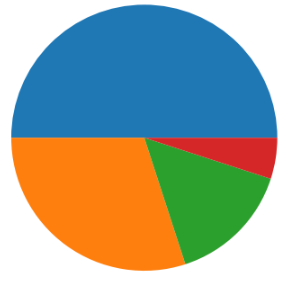

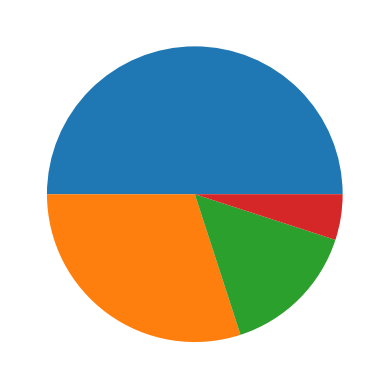

In [3]:
# code here
# 1.각각의 항목이 몇개인지 알아야 그릴 수 있음
menu_count = df["메뉴"].value_counts()
plt.pie(menu_count)
plt.show()

### **Q2. 조각에 이름표 붙이기**

방금 그린 파이 차트에 각 조각이 어떤 메뉴인지 표시해보자.


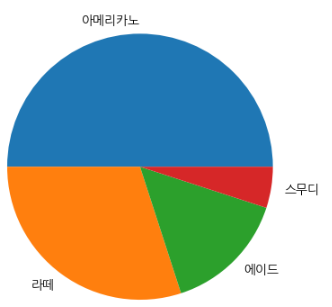

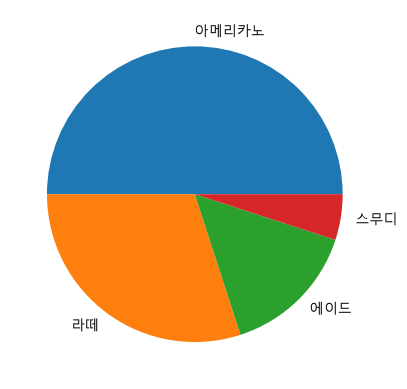

In [4]:
# code here
menu_count = df["메뉴"].value_counts()
plt.pie(menu_count, labels = menu_count.index)
plt.show()

### **Q3. 비율 표시하기**

각 조각에 비율을 소수점 1자리까지 표시해보자.


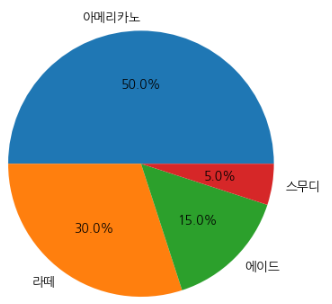

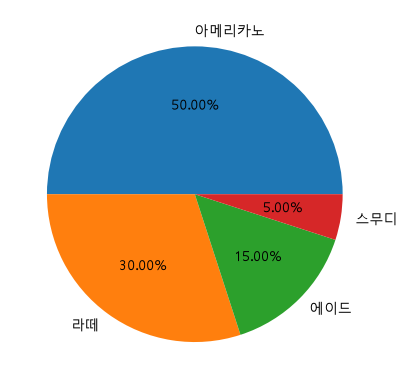

In [5]:
# code here
plt.pie(menu_count, labels = menu_count.index, autopct = "%.2f%%")
plt.show()

### **Q4. 특정 조각 떼어내서 강조하기**
- 가장 많이 팔린 '조각만 0.1만큼 떼어내보자.


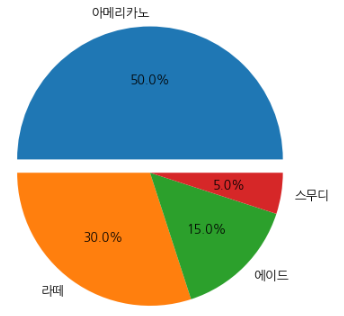

In [6]:
# Series.max(): 가장 큰값
# Series.idxmax() : 가장 큰값의 배정된 인덱스(loc) -> 반대: idxmin()
# Series.argmax() : 가장 큰값의 순서의 인덱스(iloc) -> 반대: argmin()

menu_count.argmax()

#메뉴 개수만큼 0으로 채워진 리스트 생성
explode_list = [0 for _ in range(len(menu_count))]
#가장 큰 값이 존재하는 위치에만 0.2만큼 떨어뜨리기
explode_list[menu_count.argmax()] = 0.2



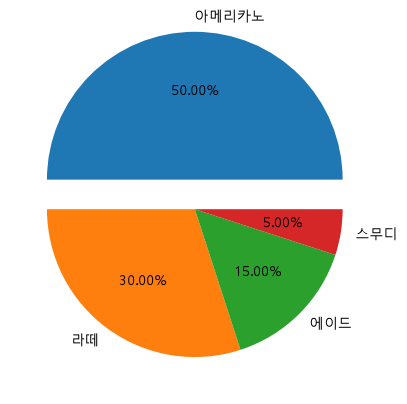

In [7]:
# code here
# 1. 가장 큰 값의 조각을 찾기
# 2. 그 부분만 리스트에 0보다 큰 값으로 설정하고 -> explode라는 옵션에 넣어주기

plt.pie(menu_count, labels = menu_count.index, autopct = "%.2f%%", explode = explode_list)
plt.show()

### **Q5. 입체적인 그림자 효과 주기**

그래프에 그림자 효과를 더해보자.


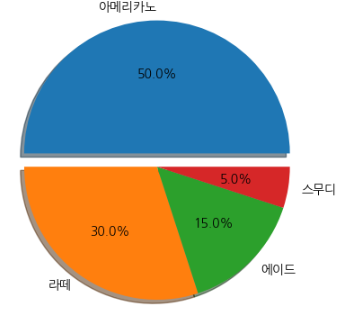

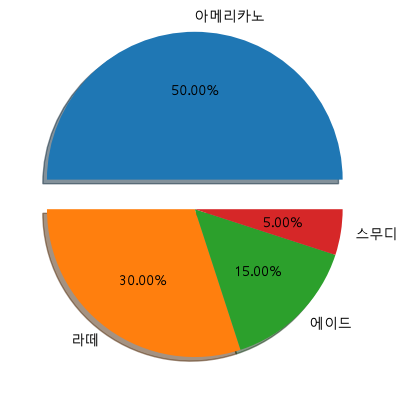

In [8]:
# code here

plt.pie(menu_count, labels = menu_count.index, autopct = "%.2f%%", explode = explode_list, shadow=True)
plt.show()

### **Q6. 시작 각도 바꾸기**

12시 방향부터 시작하도록 한다.


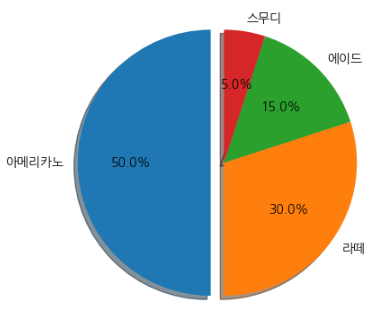

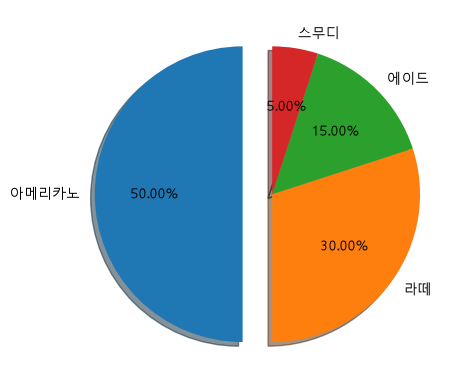

In [9]:
# code here
# startangle 
# 0도: 3시
# 90도: 12시
# 180도: 9시
# 270도: 6시

plt.pie(menu_count, labels = menu_count.index, autopct = "%.2f%%", explode = explode_list, shadow = True, startangle = 90)
plt.show()

### **Q7. 기준 이상인 조각을 모두 강조하기**

- 판매 비율이 20% 이상인 조각은 모두 explode로 떼어내보자.

  (HINT : np.where)


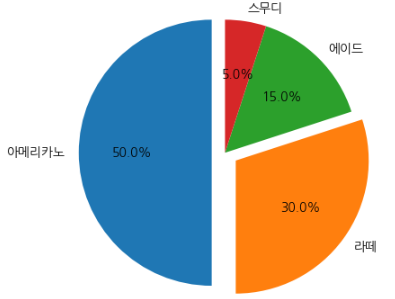

In [10]:
percent = (menu_count / menu_count.sum()) * 100

# np.where(조건, true라면 기록할 값, false라면 기록할 값)
explode_list = np.where(percent >= 20, 0.2, 0)
explode_list
percent

메뉴
아메리카노    50.0
라떼       30.0
에이드      15.0
스무디       5.0
Name: count, dtype: float64

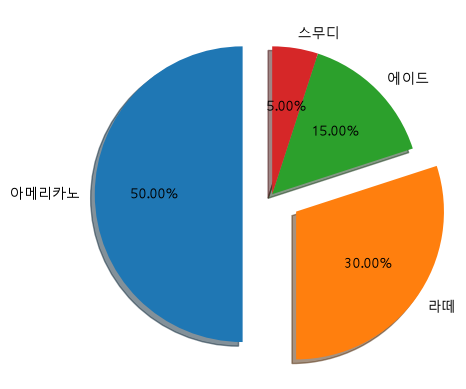

In [11]:
# code here

plt.pie(menu_count, labels = menu_count.index, autopct = "%.2f%%", explode = explode_list, shadow = True, startangle = 90)
plt.show()

### **Q8.일부 메뉴를 제외하고 다시 그리기**

전체의 10% 미만인 메뉴는 제외하고 나머지 메뉴만으로 파이 차트를 다시 그려보자.


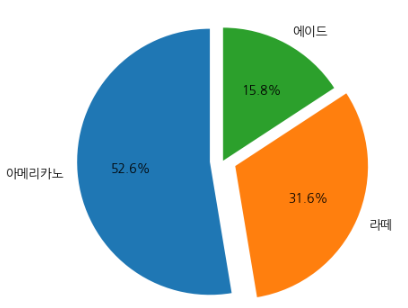

In [26]:
over10 = percent[percent > 10]
over10
new_explode_list = np.where(over10 >= 30, 0.1, 0)


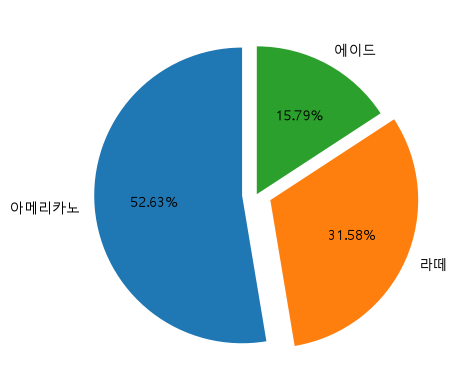

In [27]:
# code here
plt.pie(over10, labels = over10.index, autopct = "%.2f%%", explode = new_explode_list, startangle = 90)
plt.show()
